## Part A: Load the data

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset,DataLoader,Subset
from PIL import Image
from torchvision import transforms
import kagglehub

In [ ]:

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device :{device}")

Device :cuda


In [ ]:
path = kagglehub.dataset_download("arashnic/faces-age-detection-dataset")
print(path)

Using Colab cache for faster access to the 'faces-age-detection-dataset' dataset.
/kaggle/input/faces-age-detection-dataset


In [ ]:
TRAIN_DIR = os.path.join(path, 'faces')
TRAIN_IMAGES_DIR = os.path.join(TRAIN_DIR, 'Train')
TRAIN_LABELS_CSV = os.path.join(TRAIN_DIR, 'train.csv')

label_df = pd.read_csv(TRAIN_LABELS_CSV)
classes = label_df['Class'].unique().tolist()
print(classes)


['MIDDLE', 'YOUNG', 'OLD']


In [ ]:
label_df.head()

,ID,Class
0,377.jpg,MIDDLE
1,17814.jpg,YOUNG
2,21283.jpg,MIDDLE
3,16496.jpg,YOUNG
4,4487.jpg,MIDDLE


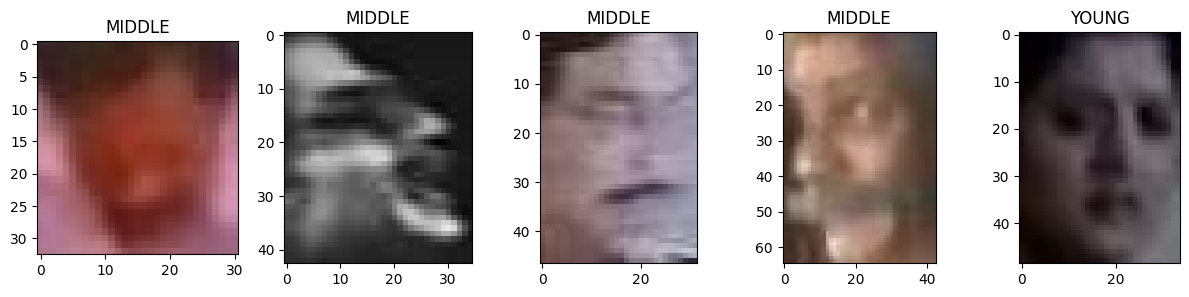

In [ ]:
samples = label_df.sample(5)

fig, axes = plt.subplots(1,5,figsize=(15, 3))

for idx, row in enumerate(samples.itertuples(index=False)):
    img_path = os.path.join(TRAIN_IMAGES_DIR, row.ID)
    sample_img = Image.open(img_path)
    axes[idx].imshow(sample_img)
    axes[idx].set_title(row.Class)

plt.show()

## Part B: Preprocess the images

In [ ]:
transform = transforms.Compose(
    [
        transforms.Resize((128,128)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5]*3,std=[0.5]*3)
    ]
)

class_map = {
    'YOUNG': 0,
    'MIDDLE': 1,
    'OLD': 2
}

label_df['Class'] = label_df["Class"].map(class_map)
label_df.sample(5)

,ID,Class
9341,23204.jpg,2
10806,8863.jpg,0
9220,7736.jpg,1
2653,18248.jpg,0
4622,12632.jpg,2


## Part C: Custom Dataset ,Split and batch

In [ ]:
class AgeDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        super().__init__()

        self.samples = []
        self.transform = transform

        directories = os.listdir(root_dir)
        if len(directories) > 2:
            # Test dataset processing
            for img_name in directories:
                img_path = os.path.join(root_dir, img_name)
                age = int(img_name.split('_')[0])
                if age <= 39:
                    label = 0  # Young
                elif age >= 40 and age <= 64:
                    label = 1  # Middle
                elif age >= 65:
                    label = 2  # Old
                self.samples.append((img_path, label))
        else:
            # Train dataset
            self.train_labels_df = pd.read_csv(os.path.join(root_dir, 'train.csv'))
            self.train_labels_df['Labels'] = self.train_labels_df['Class'].map(class_map)

            for _, row in self.train_labels_df.iterrows():
                img_path = os.path.join(root_dir, 'Train', row.ID)
                label = row.Labels
                self.samples.append((img_path, label))


    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
train_dataset_full = AgeDataset(root_dir=TRAIN_DIR, transform=transform)

In [ ]:
dataset_size = train_dataset_full.__len__()
val_size = int(dataset_size * 0.2)
train_size = dataset_size - val_size

# Rearranges the indices of the dataset
indices = torch.randperm(dataset_size, generator=torch.Generator().manual_seed(42)).tolist()
train_indices, val_indices = indices[:train_size], indices[train_size:]

train_dataset = Subset(train_dataset_full, train_indices)
val_dataset = Subset(train_dataset_full, val_indices)

In [ ]:
pin = True if device.type == 'cuda' else False

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, pin_memory=pin)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, pin_memory=pin)

## Part D: Build the CNN

In [ ]:
class MyCNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.features = nn.Sequential(
        nn.Conv2d(3,32,kernel_size=3,padding=2,stride=1),
        nn.Conv2d(32,32,kernel_size=3,padding=2,stride=1),
        nn.ReLU(),
        nn.BatchNorm2d(32),
        nn.MaxPool2d(2,2),

        nn.Conv2d(32,64,kernel_size=3,padding=1,stride=1),
        nn.Conv2d(64,64,kernel_size=3,padding=1,stride=1),
        nn.ReLU(),
        nn.BatchNorm2d(64),
        nn.MaxPool2d(2,2),

        nn.Conv2d(64,128,kernel_size=3,padding=1,stride=1),
        nn.Conv2d(128,128,kernel_size=3,padding=1,stride=1),
        nn.ReLU(),
        nn.BatchNorm2d(128),
        nn.MaxPool2d(2,2),

        nn.Conv2d(128,256,kernel_size=3,padding=1,stride=1),
        nn.Conv2d(256,256,kernel_size=3,padding=1,stride=1),
        nn.ReLU(),
        nn.BatchNorm2d(256),
        nn.MaxPool2d(2,2),
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(256*8*8,512),
        nn.ReLU(),
        nn.Dropout(0.4),#40% neuron will be off randomly to avoid overfitting
        nn.Linear(512,64),
        nn.ReLU(),
        nn.Dropout(0.4),
        nn.Linear(64,3)
    )

  def forward(self,x):
    x = self.features(x)
    x = self.classifier(x)

    return x

In [ ]:
model = MyCNN().to(device)

## Part E: Train and evaluate






In [ ]:
learning_rate = 0.001
epochs = 10
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [ ]:
tracking = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for batch_features, batch_labels in train_loader:
        batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

        outputs = model(batch_features)
        loss = criterion(outputs, batch_labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        # accuracy calculation
        _, predicted = torch.max(outputs, dim=1)
        correct += (predicted == batch_labels).sum().item()
        total += batch_labels.size(0)

    avg_train_loss = total_loss / len(train_loader)
    train_acc = correct / total

    # validation
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for val_features, val_labels in val_loader:
            val_features, val_labels = val_features.to(device), val_labels.to(device)

            outputs = model.forward(val_features)
            loss = criterion(outputs, val_labels)
            val_loss += loss.item()

            _, val_predicted = torch.max(outputs, dim=1)
            val_correct += (val_predicted == val_labels).sum().item()
            val_total += val_labels.size(0)

    avg_val_loss = val_loss / len(val_loader)
    val_acc = val_correct / val_total

    tracking['train_loss'].append(avg_train_loss)
    tracking['train_acc'].append(train_acc)
    tracking['val_loss'].append(avg_val_loss)
    tracking['val_acc'].append(val_acc)

    print(f'Epoch [{epoch+1}/{epochs}] Train Loss: {avg_train_loss:.4f}, Train Acc: {train_acc:.4f}, Val Loss: {avg_val_loss:.4f}, Val Acc: {val_acc:.4f}')

Epoch [1/10] Train Loss: 0.9274, Train Acc: 0.5807, Val Loss: 0.7770, Val Acc: 0.6604
Epoch [2/10] Train Loss: 0.8241, Train Acc: 0.6332, Val Loss: 0.7486, Val Acc: 0.6732
Epoch [3/10] Train Loss: 0.7811, Train Acc: 0.6542, Val Loss: 0.7441, Val Acc: 0.6775
Epoch [4/10] Train Loss: 0.7653, Train Acc: 0.6662, Val Loss: 0.7389, Val Acc: 0.6594
Epoch [5/10] Train Loss: 0.7351, Train Acc: 0.6806, Val Loss: 0.6618, Val Acc: 0.7104
Epoch [6/10] Train Loss: 0.7069, Train Acc: 0.6948, Val Loss: 0.6620, Val Acc: 0.7252
Epoch [7/10] Train Loss: 0.6735, Train Acc: 0.7120, Val Loss: 0.6326, Val Acc: 0.7275
Epoch [8/10] Train Loss: 0.6391, Train Acc: 0.7253, Val Loss: 0.6299, Val Acc: 0.7212
Epoch [9/10] Train Loss: 0.6037, Train Acc: 0.7409, Val Loss: 0.6698, Val Acc: 0.7162
Epoch [10/10] Train Loss: 0.5670, Train Acc: 0.7614, Val Loss: 0.6044, Val Acc: 0.7445
